In [1]:
import pandas as pd

In [2]:
file = pd.read_excel('./2025-2021.xlsx', sheet_name='Лист1')
file2 = pd.read_excel('./2025-2021.xlsx', sheet_name='Лист2')

In [7]:
file.head(20)

,Наименование показателя,Код строки,На 31 декабря 2025 г.2,На 31 декабря 2024 г.3,На 31 декабря 2023 г.4,На 31 декабря 2022 г.,На 31 декабря 2021 г.,На 31 декабря 2020 г.,Ср 2025,Ср 2024,Ср 2023,Ср 2022,Ср 2021
0,Нематериальные активы,1110.0,9 587,11 362,6 061,8 719,11 515,3 778,10474.5,8711.5,7390.0,10117.0,7646.5
1,Основные средства,1150.0,381 833,445 494,491 644,422 911,316 257,302 629,413663.5,468569.0,457277.5,369584.0,309443.0
2,Финансовые вложения,1170.0,0,44 500,10 500,0,0,0,22250.0,27500.0,5250.0,0.0,0.0
3,Отложенные налоговые активы,1180.0,55 586,12 602,19 686,15 014,14 480,58 497,34094.0,16144.0,17350.0,14747.0,36488.5
4,Прочие внеоборотные активы,1190.0,41 487,11 228,2 144,24 567,0,0,26357.5,6686.0,13355.5,12283.5,0.0
5,Итого по разделу I,1100.0,488 494,525 186,530 035,471 211,342 253,364 904,506840.0,527610.5,500623.0,406732.0,353578.5
6,Запасы,1210.0,544 877,479 684,324 572,514 415,289 139,286 941,512280.5,402128.0,419493.5,401777.0,288040.0
7,Налог на добавленную стоимость по приобретенны...,1220.0,17,319,14,282,242,1,168.0,166.5,148.0,262.0,121.5
8,Дебиторская задолженность,1230.0,8 702 717,7 239 973,5 512 487,4 584 786,5 610 150,2 158 832,7971345.0,6376230.0,5048636.5,5097468.0,3884491.0
9,Денежные средства и денежные эквиваленты,NaN,2 941,1 504,1 913,1 084,1 202,987,2222.5,1708.5,1498.5,1143.0,1094.5


In [14]:
file2.head(20)

,Наименование показателя,Код строки,За 2025 г.2,За 2024 г.3,За 2023 г.,За 2022 г.,За 2021 г.
0,Выручка,2110.0,8 366 921,6 493 136,5 797 340,4 685 433,4 078 159
1,Себестоимость продаж,2120.0,(5 923 267),(4 958 377),(4 388 532),(3 688 930),(3 328 217)
2,Валовая прибыль (убыток),2100.0,2 443 654,1 534 759,1 408 808,996 503,749 942
3,Коммерческие расходы,2210.0,(595 404),(522 258),(451 231),(311 891),(322 396)
4,Управленческие расходы,2220.0,(104 728),(88 304),(80 565),(59 510),(62 616)
5,Прибыль (убыток) от продаж,2200.0,1 743 522,924 197,877 012,625 102,364 930
6,Проценты к получению,2320.0,4 373,37 992,245,134,77
7,Проценты к уплате,2330.0,(461 963),(113 866),(131 613),(198 868),(68 133)
8,Прочие доходы,2340.0,37 246,127 036,105 005,143 676,284 223
9,Прочие расходы,2350.0,(895 280),(147 563),(264 319),(407 070),(338 239)


## Перечень обязательных финансовых показателей для анализа
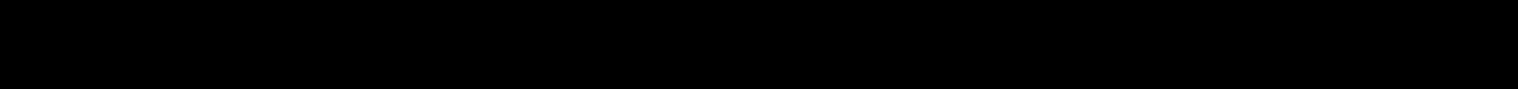
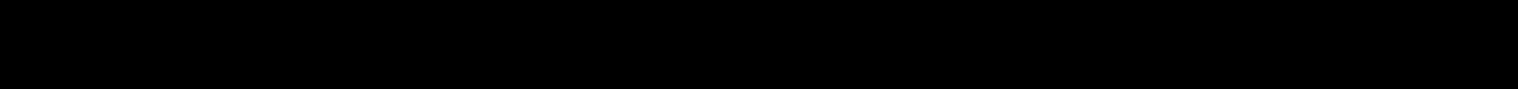
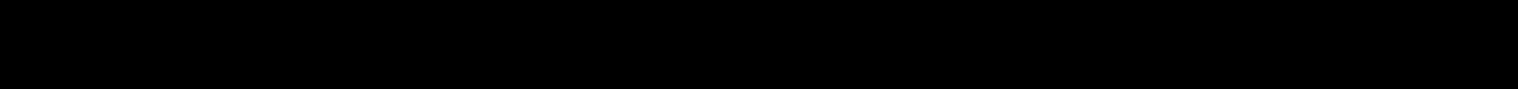

### 1. Показатели ликвидности и платежеспособности
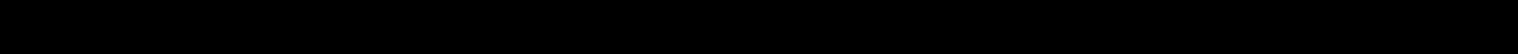

Классификация активов по ликвидности:
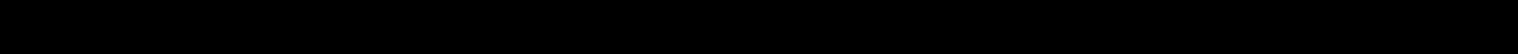

А1 – Наиболее ликвидные активы
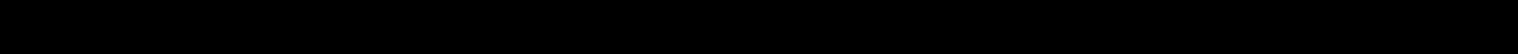

In [4]:
# Перевод в int
for idx in range(2, 7):
  col_name = file.columns[idx]
  file[col_name] = (
      pd.to_numeric(
          file[col_name]
          .astype(str)
          .str.replace(' ', '', regex=False)
          .str.replace('\xa0', '', regex=False)
          .str.replace(',', '.', regex=False),
          errors='coerce',
      )
      .fillna(0)
      .astype(int)
  )

In [7]:
A1 = (
    file[file.iloc[:, 0] == "Денежные средства и денежные эквиваленты"].iloc[
        0, 2:7
    ]
    + file[file.iloc[:, 0] == "Финансовые вложения"].iloc[0, 2:7]
)

display(A1)

На 31 декабря 2025 г.2     2941
На 31 декабря 2024 г.3    46004
На 31 декабря 2023 г.4    12413
На 31 декабря 2022 г.      1084
На 31 декабря 2021 г.      1202
dtype: object

А2 – Быстрореализуемые активы

In [9]:
A2 = (
    file[file.iloc[:, 0] == "Дебиторская задолженность"].iloc[0, 2:7]
    + file[file.iloc[:, 0] == "Запасы"].iloc[0, 2:7]
    + file[file.iloc[:, 0] == "Прочие оборотные активы"].iloc[0, 2:7]
)

display(A2)

На 31 декабря 2025 г.2    9353333
На 31 декабря 2024 г.3    7747449
На 31 декабря 2023 г.4    5845323
На 31 декабря 2022 г.     5105865
На 31 декабря 2021 г.     5908899
dtype: object

А3 – Медленно реализуемые активы
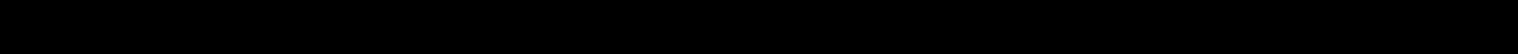

In [11]:
A3 = (
    file[file.iloc[:, 0] == "Запасы"].iloc[0, 2:7]
    + file[file.iloc[:, 0] == "Налог на добавленную стоимость по приобретенным ценностям"].iloc[0, 2:7]
    + file[file.iloc[:, 0] == "Прочие оборотные активы"].iloc[0, 2:7]
)

display(A3)

На 31 декабря 2025 г.2    650633
На 31 декабря 2024 г.3    507795
На 31 декабря 2023 г.4    332850
На 31 декабря 2022 г.     521361
На 31 декабря 2021 г.     298991
dtype: object

А4 – Труднореализуемые активы

In [12]:
A4 = (
    file[file.iloc[:, 0] == "Итого по разделу I"].iloc[0, 2:7]
)

display(A4)

На 31 декабря 2025 г.2    488494
На 31 декабря 2024 г.3    525186
На 31 декабря 2023 г.4    530035
На 31 декабря 2022 г.     471211
На 31 декабря 2021 г.     342253
Name: 5, dtype: object

In [13]:
current = (
    file[file.iloc[:, 0] == "Итого по разделу II"].iloc[0, 2:7]
)

display(current)

На 31 декабря 2025 г.2    9356291
На 31 декабря 2024 г.3    7749272
На 31 декабря 2023 г.4    5847250
На 31 декабря 2022 г.     5107231
На 31 декабря 2021 г.     5910343
Name: 12, dtype: object

In [14]:
short = (
    file[file.iloc[:, 0] == "Итого по разделу V"].iloc[0, 2:7]
)

display(short)

На 31 декабря 2025 г.2    3683576
На 31 декабря 2024 г.3    3823431
На 31 декабря 2023 г.4    4104128
На 31 декабря 2022 г.     3732182
На 31 декабря 2021 г.     3201400
Name: 27, dtype: object

Коэффициент абсолютной ликвидности

In [15]:
A1 / short

На 31 декабря 2025 г.2    0.000798
На 31 декабря 2024 г.3    0.012032
На 31 декабря 2023 г.4    0.003025
На 31 декабря 2022 г.      0.00029
На 31 декабря 2021 г.     0.000375
dtype: object

Коэффициент быстрой (срочной) ликвидности

In [16]:
(A1 + A2) / short

На 31 декабря 2025 г.2    2.539998
На 31 декабря 2024 г.3     2.03834
На 31 декабря 2023 г.4    1.427279
На 31 декабря 2022 г.     1.368355
На 31 декабря 2021 г.     1.846099
dtype: object

Коэффициент текущей ликвидности

In [17]:
current / short

На 31 декабря 2025 г.2    2.540002
На 31 декабря 2024 г.3    2.026785
На 31 декабря 2023 г.4    1.424724
На 31 декабря 2022 г.      1.36843
На 31 декабря 2021 г.     1.846174
dtype: object

### 2. Показатели финансовой устойчивости

Коэффициент автономии (независимости)
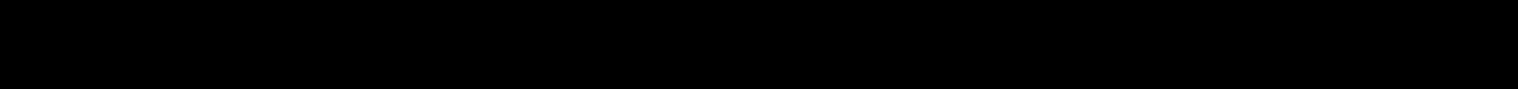

Коэффициент финансового рычага (плечо финансового рычага)

Коэффициент обеспеченности собственными оборотными средствами

Коэффициент долгосрочной финансовой независимости

### 3. Показатели рентабельности (эффективности)

Рентабельность продаж (ROS)
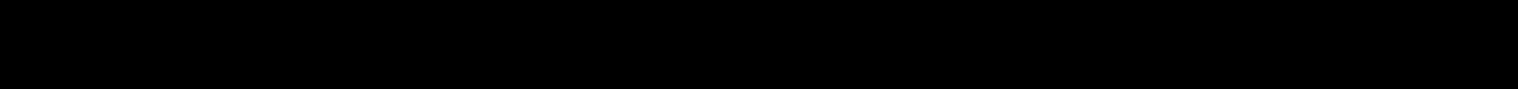

Рентабельность активов (ROA)

Рентабельность собственного капитала (ROE)

Рентабельность продукции (себестоимости)

### 4. Показатели деловой активности (оборачиваемости)

Оборачиваемость дебиторской задолженности

Оборачиваемость запасов
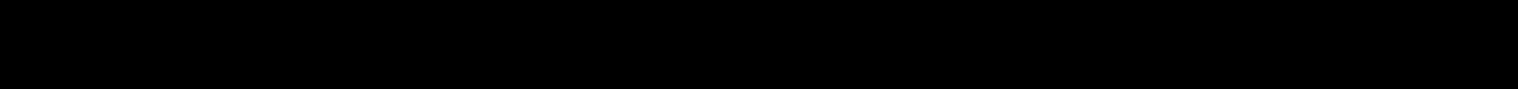

Оборачиваемость активов

### 5. Абсолютные показатели прибыли
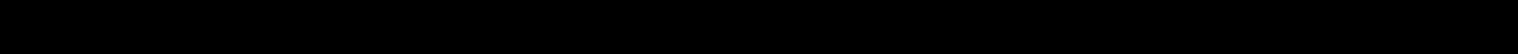

Валовая прибыль
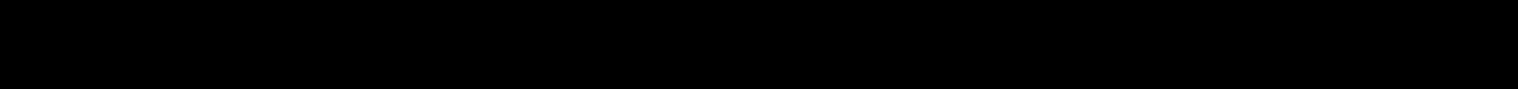

Прибыль до налогообложения

Чистая прибыль
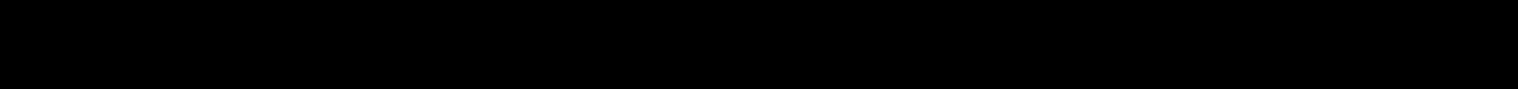